# DenguePharma Analytics — pesquisa reproduzível

Pergunta clínica: em pacientes com dengue estabelecida, quais intervenções apresentam benefício, alívio sintomático ou sinais de dano?

Este notebook descreve **um corpus piloto por execução**. Metadados coletados ainda podem conter registros inelegíveis. As conclusões clínicas dependem de seleção e resultados revisados. Execute com o Python de `analytics/.venv` ou com o script documentado. Nenhuma coleta, curadoria ou publicação é realizada aqui.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image
from denguepharma_analytics.storage import default_root, require_published, public_summary, query_table, run_path

run_id = os.environ.get("DENGUEPHARMA_RUN_ID", "7a1897915598231a92e7b969185fc13d33e23d88e245d5c015bab26b13984424")
root = default_root()
manifest = require_published(root, run_id)
summary = public_summary(root, run_id)
folder = run_path(root, run_id)
display(pd.DataFrame([{
    "run_id": run_id, "input_hash": manifest["input_hash"],
    "code_hash": manifest["code_hash"], "version": manifest["version"],
    "protocol": str(manifest["protocol"]),
}]))

# Leitura paginada pela mesma interface pública usada pela aplicação.
# Nenhuma transformação científica é reimplementada no notebook.
def table(name):
    first = query_table(root, run_id, name, limit=1000)
    rows = list(first["rows"])
    for offset in range(1000, first["total"], 1000):
        rows.extend(query_table(root, run_id, name, offset=offset, limit=1000)["rows"])
    assert len(rows) == first["total"]
    columns = [field["name"] for field in manifest["tables"][name]["schema"]]
    return pd.DataFrame(rows, columns=columns)

def show(name):
    display(Markdown(f"**Tabela: {name} — {manifest['tables'][name]['rows']} linhas**"))
    frame = table(name)
    display(frame if not frame.empty else Markdown("Sem dados nesta execução."))

def figure(name):
    path = folder / "figures" / name
    if path.is_file():
        display(Image(filename=str(path)))

,run_id,input_hash,code_hash,version,protocol
0,7a1897915598231a92e7b969185fc13d33e23d88e245d5...,fb8d1a58ed83ac29dd5391cb4184402e5d46523d7d0bef...,cc710540ae6ee2b59caf670a013c577fe40f9ccf365483...,0.14.0,{'code': 'CLINICAL-CALIBRATION-2cac6ec6-7740-4...


## 1. Panorama e limites do corpus

Documentos, registros e estudos revisados são unidades distintas. Registros consolidados por NCT não comprovam identidade clínica. Não somar participantes ou os dois pilotos. Ano de publicação e início do ensaio são variáveis diferentes. Datas posteriores ao corte permanecem sinalizadas para conferência; não são corrigidas por inferência.

In [2]:
display(pd.DataFrame([{k: summary.get(k) for k in ("documentCount", "publicationCount", "trialCount", "studyCount", "distinctConfirmedStudyCount")}]))
show("corpus_temporal")
show("corpus_temporal_flags")
show("corpus_distributions")
show("corpus_enrollment")

,documentCount,publicationCount,trialCount,studyCount,distinctConfirmedStudyCount
0,20,10,10,0,20


**Tabela: corpus_temporal — 9 linhas**

,field,category,unit,population,count,denominator,proportion,overlapping
0,publication_year,2026,publicacao,corpus_coletado,8,10,0.8,False
1,publication_year,2027,publicacao,corpus_coletado,2,10,0.2,False
2,start_year,2011,registro_ensaio,corpus_coletado,1,10,0.1,False
3,start_year,2013,registro_ensaio,corpus_coletado,1,10,0.1,False
4,start_year,2014,registro_ensaio,corpus_coletado,1,10,0.1,False
5,start_year,2015,registro_ensaio,corpus_coletado,1,10,0.1,False
6,start_year,2017,registro_ensaio,corpus_coletado,2,10,0.2,False
7,start_year,2022,registro_ensaio,corpus_coletado,2,10,0.2,False
8,start_year,2025,registro_ensaio,corpus_coletado,2,10,0.2,False


**Tabela: corpus_temporal_flags — 2 linhas**

,document_id,publication_year,status
0,2f708375-35a1-48f4-abbd-1a0618e90e37,2027,ANO_BIBLIOGRAFICO_APOS_CORTE_CONFERIR_FONTE
1,ef8f24f8-b92f-4ea4-ae13-8778882cb3bc,2027,ANO_BIBLIOGRAFICO_APOS_CORTE_CONFERIR_FONTE


**Tabela: corpus_distributions — 42 linhas**

,field,category,unit,population,count,denominator,proportion,overlapping
0,context,NAO_CLASSIFICADO,documento,corpus_coletado,20,20,1.0,False
1,countries,Colombia,registro_ensaio,corpus_coletado,1,10,0.1,True
2,countries,France,registro_ensaio,corpus_coletado,1,10,0.1,True
3,countries,Indonesia,registro_ensaio,corpus_coletado,1,10,0.1,True
4,countries,Panama,registro_ensaio,corpus_coletado,1,10,0.1,True
5,countries,Philippines,registro_ensaio,corpus_coletado,1,10,0.1,True
6,countries,Puerto Rico,registro_ensaio,corpus_coletado,1,10,0.1,True
7,countries,Singapore,registro_ensaio,corpus_coletado,2,10,0.2,True
8,countries,Sudan,registro_ensaio,corpus_coletado,1,10,0.1,True
9,countries,Thailand,registro_ensaio,corpus_coletado,2,10,0.2,True


**Tabela: corpus_enrollment — 3 linhas**

,field,unit,available,denominator,missing,min,max,median,q1,q3,sumsParticipants
0,enrollment_actual,registro_ensaio,8,10,2,20.0,8173.0,182.0,74.0,353.25,False
1,enrollment_estimated,registro_ensaio,2,10,8,200.0,266.0,233.0,216.5,249.50,False
2,enrollment_unknown_type,registro_ensaio,0,10,10,NaN,NaN,NaN,NaN,NaN,False


## 2. Patrocinadores e disponibilidade documental

Categorias são as declaradas pelas fontes; nomes não passaram por resolução institucional. Patrocinador não equivale a financiador ou risco de viés. Completude mede disponibilidade, sem pontuação de qualidade metodológica. Numeradores, denominadores e ausências permanecem nas tabelas.

**Tabela: corpus_sponsor_distributions — 9 linhas**

,field,category,status,unit,count,denominator,proportion
0,sponsor_name,gadjah mada university,PRESENTE,registro_consolidado_por_NCT_ou_documento,1,10,0.1
1,sponsor_name,national institute of allergy and infectious d...,PRESENTE,registro_consolidado_por_NCT_ou_documento,2,10,0.2
2,sponsor_name,research and publication office,PRESENTE,registro_consolidado_por_NCT_ou_documento,1,10,0.1
3,sponsor_name,takeda,PRESENTE,registro_consolidado_por_NCT_ou_documento,4,10,0.4
4,sponsor_name,"university hospital, strasbourg, france",PRESENTE,registro_consolidado_por_NCT_ou_documento,1,10,0.1
5,sponsor_name,"university of maryland, baltimore",PRESENTE,registro_consolidado_por_NCT_ou_documento,1,10,0.1
6,sponsor_type,INDUSTRY,PRESENTE,registro_consolidado_por_NCT_ou_documento,4,10,0.4
7,sponsor_type,NIH,PRESENTE,registro_consolidado_por_NCT_ou_documento,2,10,0.2
8,sponsor_type,OTHER,PRESENTE,registro_consolidado_por_NCT_ou_documento,4,10,0.4


**Tabela: corpus_sponsor_completeness — 2 linhas**

,field,unit,present,missing,conflicts,denominator,proportion
0,sponsor_name,registro_consolidado_por_NCT_ou_documento,10,0,0,10,1.0
1,sponsor_type,registro_consolidado_por_NCT_ou_documento,10,0,0,10,1.0


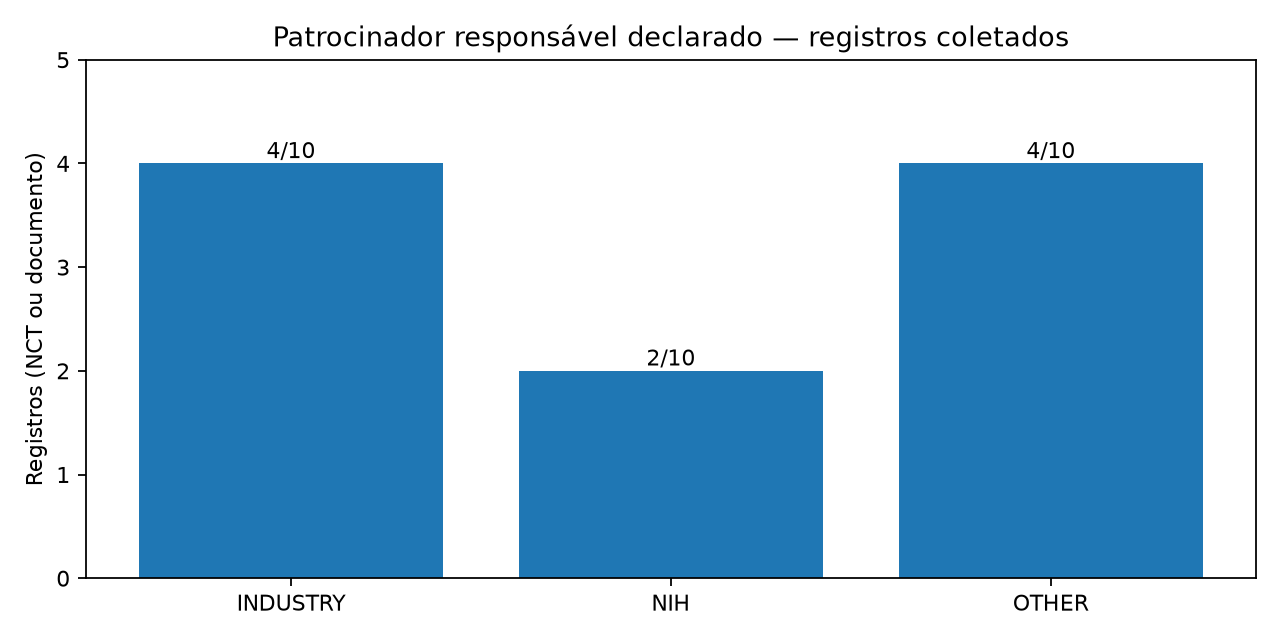

**Tabela: corpus_completeness — 12 linhas**

,source,field,unit,review_status,present,applicable,total,conflicts,not_applicable,missing,proportion
0,CLINICALTRIALS,countries,registro_ensaio,METADADO_DA_FONTE,10,10,10,0,0,0,1.0
1,CLINICALTRIALS,design,registro_ensaio,METADADO_DA_FONTE,10,10,10,0,0,0,1.0
2,CLINICALTRIALS,enrollment,registro_ensaio,METADADO_DA_FONTE,10,10,10,0,0,0,1.0
3,CLINICALTRIALS,has_results,registro_ensaio,METADADO_DA_FONTE,10,10,10,0,0,0,1.0
4,CLINICALTRIALS,phases,registro_ensaio,METADADO_DA_FONTE,7,7,10,0,3,0,1.0
5,CLINICALTRIALS,recruitment,registro_ensaio,METADADO_DA_FONTE,10,10,10,0,0,0,1.0
6,CLINICALTRIALS,start_year,registro_ensaio,METADADO_DA_FONTE,10,10,10,0,0,0,1.0
7,CLINICALTRIALS,substances,registro_ensaio,METADADO_DA_FONTE,9,10,10,0,0,1,0.9
8,PUBMED,identifiers,publicacao,METADADO_DA_FONTE,10,10,10,0,0,0,1.0
9,PUBMED,journal,publicacao,METADADO_DA_FONTE,10,10,10,0,0,0,1.0


In [3]:
show("corpus_sponsor_distributions")
show("corpus_sponsor_completeness")
figure("sponsors-types.png")
show("corpus_completeness")

## 3. Relato de resultados

Disponibilidade no registro e publicação vinculada são indicadores diferentes. Os intervalos abaixo são dias de calendário entre campos do registro, entre pares elegíveis segundo o protocolo de auditoria; não representam sobrevida dos pacientes. Não há censura, Kaplan–Meier ou imputação de datas parciais.

,censoring,completed,endpoint,max,median,min,observed,origin,q1,q3,total_trials,unit
0,False,8,resultsFirstPostDateStruct.date,1288,709.0,469,5,primaryCompletionDateStruct.date,709.0,725.0,10,dias_de_calendario


**Tabela: reporting_availability — 11 linhas**

,field,category,unit,count,denominator,proportion
0,interval_status,CALCULAVEL,registro_consolidado_por_NCT_ou_documento,5,10,0.5
1,interval_status,CONFERENCIA_NECESSARIA,registro_consolidado_por_NCT_ou_documento,5,10,0.5
2,last_update_precision,DIA,registro_consolidado_por_NCT_ou_documento,10,10,1.0
3,overall_status,ACTIVE_NOT_RECRUITING,registro_consolidado_por_NCT_ou_documento,1,10,0.1
4,overall_status,COMPLETED,registro_consolidado_por_NCT_ou_documento,8,10,0.8
5,overall_status,TERMINATED,registro_consolidado_por_NCT_ou_documento,1,10,0.1
6,primary_precision,DIA,registro_consolidado_por_NCT_ou_documento,10,10,1.0
7,result_category,DISPONIVEL,registro_consolidado_por_NCT_ou_documento,6,10,0.6
8,result_category,NAO_DECLARADO_DISPONIVEL,registro_consolidado_por_NCT_ou_documento,4,10,0.4
9,results_precision,AUSENTE,registro_consolidado_por_NCT_ou_documento,4,10,0.4


**Tabela: reporting_intervals — 1 linhas**

,origin,endpoint,unit,observed,completed,total_trials,min,max,median,q1,q3,censoring
0,primaryCompletionDateStruct.date,resultsFirstPostDateStruct.date,dias_de_calendario,5,8,10,469,1288,709.0,709.0,725.0,False


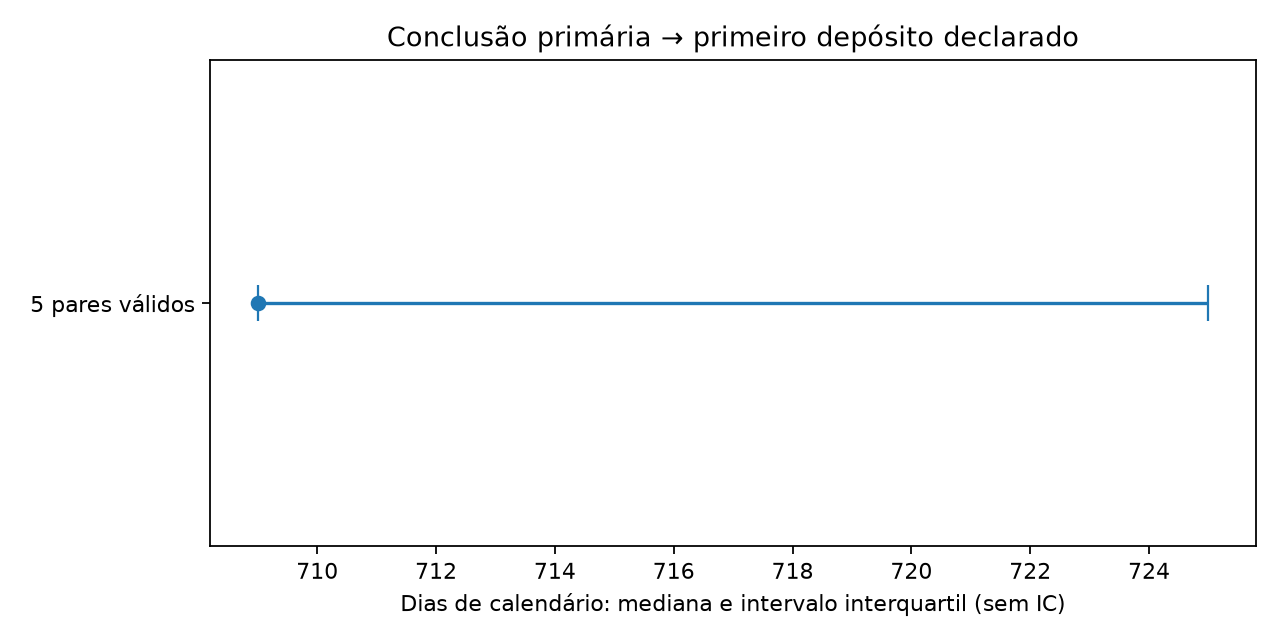

In [4]:
display(pd.DataFrame([summary["reporting"]["interval_summary"]]))
show("reporting_availability")
show("reporting_intervals")
figure("reporting-intervals.png")

## 4. Referências e lacunas bibliográficas

RESULT, DERIVED e BACKGROUND preservam os códigos da fonte. Coincidência por PMID é candidato bibliográfico, sem confirmar vínculo clínico ou suporte semântico. Ausência no corpus não significa inexistência de publicação ou evidência. Tipos podem compartilhar PMIDs. Denominador zero permanece ausente, sem percentual artificial.

**Tabela: publication_reference_coverage — 3 linhas**

,reference_type,total_registry_units,registry_units_with_references,registry_units_with_valid_pmid,registry_units_with_candidate,distinct_valid_pmids,valid_pmids_in_corpus,not_retrieved_pmids,missing_or_invalid_entries,registry_reference_proportion,pmid_coverage_proportion
0,BACKGROUND,10,1,1,0,57,0,57,6,0.1,0.0
1,DERIVED,10,5,5,0,14,0,14,0,0.5,0.0
2,RESULT,10,0,0,0,0,0,0,0,0.0,NaN


**Tabela: publication_reference_missing — 71 linhas**

,pmid,source_url,trial_ids_json,reference_types_json,trial_references_json,status
0,10497982,https://pubmed.ncbi.nlm.nih.gov/10497982/,"[""NCT03055585""]","[""BACKGROUND""]","[{""accessStatus"":""TEXTO_COMPLETO"",""contentHash...",NAO_RECUPERADO_NO_CORPUS
1,10547686,https://pubmed.ncbi.nlm.nih.gov/10547686/,"[""NCT03055585""]","[""BACKGROUND""]","[{""accessStatus"":""TEXTO_COMPLETO"",""contentHash...",NAO_RECUPERADO_NO_CORPUS
2,1350096,https://pubmed.ncbi.nlm.nih.gov/1350096/,"[""NCT03055585""]","[""BACKGROUND""]","[{""accessStatus"":""TEXTO_COMPLETO"",""contentHash...",NAO_RECUPERADO_NO_CORPUS
3,15003657,https://pubmed.ncbi.nlm.nih.gov/15003657/,"[""NCT03055585""]","[""BACKGROUND""]","[{""accessStatus"":""TEXTO_COMPLETO"",""contentHash...",NAO_RECUPERADO_NO_CORPUS
4,15691147,https://pubmed.ncbi.nlm.nih.gov/15691147/,"[""NCT03055585""]","[""BACKGROUND""]","[{""accessStatus"":""TEXTO_COMPLETO"",""contentHash...",NAO_RECUPERADO_NO_CORPUS
...,...,...,...,...,...,...
66,41297006,https://pubmed.ncbi.nlm.nih.gov/41297006/,"[""NCT05048875""]","[""DERIVED""]","[{""accessStatus"":""TEXTO_COMPLETO"",""contentHash...",NAO_RECUPERADO_NO_CORPUS
67,42480195,https://pubmed.ncbi.nlm.nih.gov/42480195/,"[""NCT01511250""]","[""DERIVED""]","[{""accessStatus"":""TEXTO_COMPLETO"",""contentHash...",NAO_RECUPERADO_NO_CORPUS
68,4940475,https://pubmed.ncbi.nlm.nih.gov/4940475/,"[""NCT03055585""]","[""BACKGROUND""]","[{""accessStatus"":""TEXTO_COMPLETO"",""contentHash...",NAO_RECUPERADO_NO_CORPUS
69,7124721,https://pubmed.ncbi.nlm.nih.gov/7124721/,"[""NCT03055585""]","[""BACKGROUND""]","[{""accessStatus"":""TEXTO_COMPLETO"",""contentHash...",NAO_RECUPERADO_NO_CORPUS


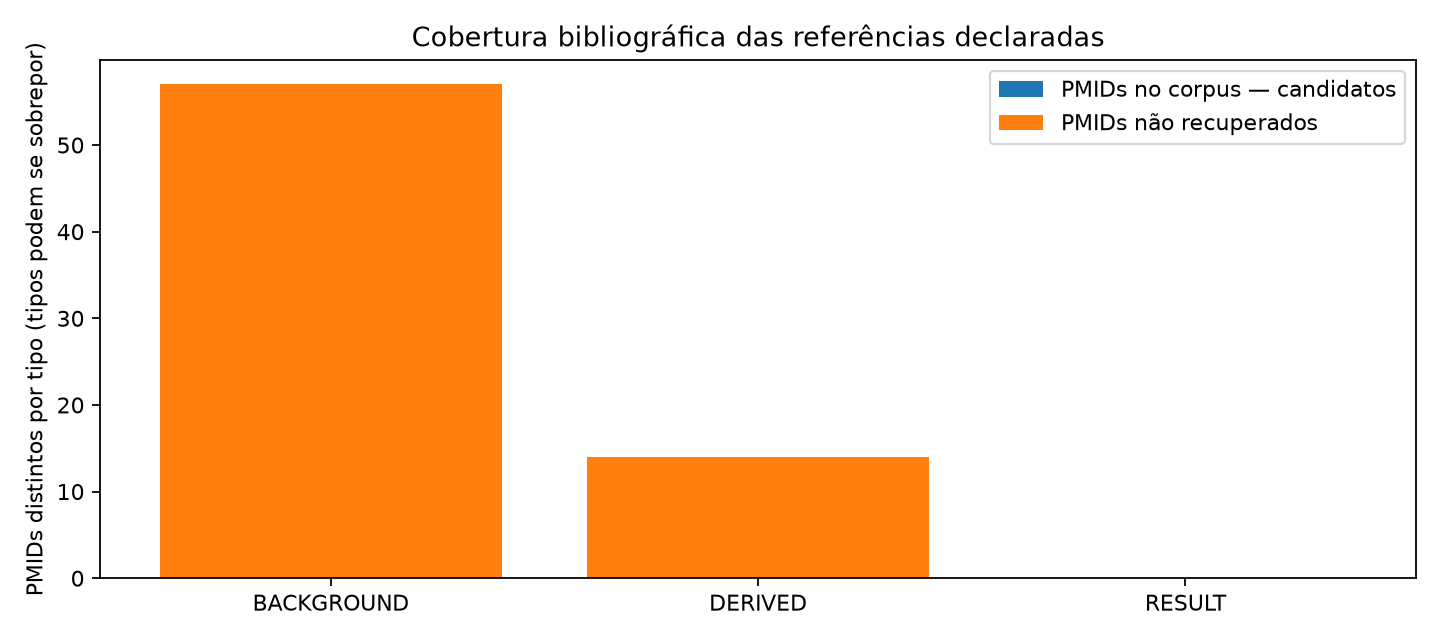

In [5]:
show("publication_reference_coverage")
show("publication_reference_missing")
figure("publication-refs-coverage.png")

## 5. Resposta clínica disponível nesta execução

A síntese usa exclusivamente resultados aprovados e publicados. Um panorama amplo de registros não responde quais medicamentos funcionam. Resultados vazios não autorizam classificar tratamentos como ineficazes nem afirmar ausência de estudos elegíveis. As categorias clínicas dependem de julgamento humano documentado por comparação, população, desfecho e tempo.

In [6]:
display(pd.DataFrame([summary["clinical"]]))
show("mart_panorama")
show("clinical_results")
show("clinical_synthesis")
if not summary["clinical"]["reviewed_results"]:
    display(Markdown("**Sem resultados clínicos revisados nesta execução. Ainda não é possível concluir quais intervenções beneficiam pacientes com dengue.**"))

,available,conflicts,included_studies,notice,protocol_hash,reviewed_results,reviewed_studies,screening_counts,status,synthesis_groups
0,False,0,0,"Sem meta-analise, ranking ou recomendacao tera...",None,0,0,{},SEM_RESULTADOS_CLINICOS_REVISADOS,0


**Tabela: mart_panorama — 0 linhas**

Sem dados nesta execução.

**Tabela: clinical_results — 0 linhas**

Sem dados nesta execução.

**Tabela: clinical_synthesis — 0 linhas**

Sem dados nesta execução.

**Sem resultados clínicos revisados nesta execução. Ainda não é possível concluir quais intervenções beneficiam pacientes com dengue.**

## 6. Reprodução e próximos passos

Os módulos Python geram as tabelas; este notebook apenas as consulta. Os hashes abaixo permitem conferir equivalência entre execuções sem depender do estilo visual do HTML. A entrada e o manifesto publicados são imutáveis e verificados. A execução registra seu ambiente em um manifesto separado.

Próximo marco científico: concluir seleção independente, adjudicar divergências, revisar resultados por braço/comparação/população/tempo e avaliar limitações metodológicas. A coleta completa continua sujeita à calibração prevista no protocolo. Não há ranking de medicamentos, meta-análise ou recomendação terapêutica.

In [7]:
display(pd.DataFrame([
    {"table": name, "rows": meta["rows"], "logical_hash": meta["logical_hash"]}
    for name, meta in sorted(manifest["tables"].items()) if meta["public"]
]))
assert require_published(root, run_id) == manifest, "A execução publicada mudou durante a leitura."
print("Integridade verificada; somente tabelas públicas foram consultadas.")

,table,rows,logical_hash
0,calibration_documents,20,594c5e04ec9151c5bfab84340eeee0895fcd420d1f9470...
1,calibration_intervention_types,3,ff832f9cc6f5df9960a587d2e76ef0780a7cf711ea4661...
2,calibration_searches,2,21371637be0649dc4eb6f0bf867c284968194dc74d7267...
3,calibration_signals,18,905d31c35cea572e853261943738be454ab28b0e978e95...
4,clinical_absences,0,4f53cda18c2baa0c0354bb5f9a3ecbe5ed12ab4d8e11ba...
5,clinical_conflicts,0,4f53cda18c2baa0c0354bb5f9a3ecbe5ed12ab4d8e11ba...
6,clinical_references,0,4f53cda18c2baa0c0354bb5f9a3ecbe5ed12ab4d8e11ba...
7,clinical_results,0,4f53cda18c2baa0c0354bb5f9a3ecbe5ed12ab4d8e11ba...
8,clinical_screening,0,4f53cda18c2baa0c0354bb5f9a3ecbe5ed12ab4d8e11ba...
9,clinical_synthesis,0,4f53cda18c2baa0c0354bb5f9a3ecbe5ed12ab4d8e11ba...


Integridade verificada; somente tabelas públicas foram consultadas.
